# <b>  <FONT SIZE=6 COLOR="F5950F"> Case Study 6 — Cats vs Dogs CNN</FONT></b>
> <FONT SIZE=5 COLOR="0CB2FF"> - Estimated runtime: 10–20 minutes on Colab CPU (faster on GPU)  
Generated: 2025-10-31 15:37<br>
<FONT SIZE=5 COLOR="0CB2FF"> - This follows the Case Study 1 structure (Parts 0–5).</FONT>


In [ ]:
# let Colab access my Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# path
path="/content/drive/MyDrive/MsMLAI/Parte2/W10_Capstone-Submission/data"

## <b> <FONT SIZE=6 COLOR="F5950F"> Part 0 — Setup (Ungraded)</b>

In [ ]:
# ---- Part 0: Setup ----
import os, random, numpy as np, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_DIR = path  # use your mounted Google Drive dataset path with subfolders 'cats' and 'dogs'
USE_TFDS_FALLBACK = True  # set True to use TFDS 'cats_vs_dogs' if available
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS_CNN = 5

print("TensorFlow:", tf.__version__)


TensorFlow: 2.19.0


<b> <FONT SIZE=6 COLOR="F5950F"> Environment & GPU Check</FONT>

<FONT SIZE=5 COLOR="DC00FF"> Runtime Status</FONT><br>

><FONT SIZE=5 COLOR="0CB2FF"> - Verify TensorFlow/TFDS versions and confirm CUDA device availability.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> - List physical/logical GPUs and enable memory growth to avoid full VRAM preallocation.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> - Optionally print <i>nvidia-smi</i> output for driver and runtime diagnostics.</FONT><br><br>


In [ ]:
# Environment & GPU check
import tensorflow as tf
import tensorflow_datasets as tfds
import subprocess

print("TensorFlow:", tf.__version__)
print("TFDS:", tfds.__version__)

gpus = tf.config.list_physical_devices('GPU')
print("GPU available?", len(gpus) > 0)
print("Physical GPU devices:", gpus)

# Optional: print logical devices and set memory growth (safe if GPU exists)
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print("Logical GPU devices:", logical_gpus)
    except Exception as e:
        print("Could not set memory growth:", e)

    # Optional: show NVIDIA driver/runtime details (works on Colab)
    try:
        print("\n=== nvidia-smi ===")
        out = subprocess.check_output(["nvidia-smi"], text=True)
        print(out)
    except Exception as e:
        print("nvidia-smi not available or failed:", e)

TensorFlow: 2.19.0
TFDS: 4.9.9
GPU available? True
Physical GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Logical GPU devices: [LogicalDevice(name='/device:GPU:0', device_type='GPU')]

=== nvidia-smi ===
Mon Dec  8 21:24:33 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                  

<FONT SIZE=6 COLOR="Orange">Data Preparation & Preview</FONT>

<b> <FONT SIZE=5 COLOR="DC00FF">Clean visualization</FONT></b>

> <FONT SIZE=5 COLOR="0CB2FF"> - Preview a non-augmented validation batch to inspect image quality and labels.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> - Rescale/clip to [0,1] for display-only to avoid Matplotlib range warnings and artifacts.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> - Show 8–12 samples with class titles; this does not alter the training pipeline.</FONT><br><br>

In [ ]:
# --- Quick rebuild of train/val/test if missing (local folders: 'cats' and 'dogs') ---
import os, tensorflow as tf
AUTOTUNE = tf.data.AUTOTUNE

def preprocess(img, label):
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def augment_pair(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, 0.05)
    return img, label

def make_ds_local(data_dir, val_split=0.2, test_split=0.1, augment=True):
    train = tf.keras.utils.image_dataset_from_directory(
        data_dir, validation_split=val_split+test_split, subset="training",
        seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode="int"
    )
    valtest = tf.keras.utils.image_dataset_from_directory(
        data_dir, validation_split=val_split+test_split, subset="validation",
        seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode="int"
    )
    # split validation vs test from the held-out chunk
    val_batches = int(len(valtest) * (val_split/(val_split+test_split)))
    val = valtest.take(val_batches)
    test = valtest.skip(val_batches)

    train = train.map(preprocess, num_parallel_calls=AUTOTUNE)
    if augment:
        train = train.map(augment_pair, num_parallel_calls=AUTOTUNE)
    val = val.map(preprocess, num_parallel_calls=AUTOTUNE)
    test = test.map(preprocess, num_parallel_calls=AUTOTUNE)

    return train.prefetch(AUTOTUNE), val.prefetch(AUTOTUNE), test.prefetch(AUTOTUNE)

# Build only if missing
if 'val_ds' not in globals() or 'train_ds' not in globals() or 'test_ds' not in globals():
    assert DATA_DIR and os.path.isdir(DATA_DIR), "DATA_DIR must point to folder with 'cats' and 'dogs'."
    train_ds, val_ds, test_ds = make_ds_local(DATA_DIR, augment=True)
    class_names = ["cats", "dogs"]  # keep consistent with your local folder names
    print("Datasets rebuilt from local path:", DATA_DIR)
else:
    print("Datasets already present. Skipping rebuild.")

Found 697 files belonging to 2 classes.
Using 488 files for training.
Found 697 files belonging to 2 classes.
Using 209 files for validation.
Datasets rebuilt from local path: /content/drive/MyDrive/MsMLAI/Parte2/W10_Capstone-Submission/data


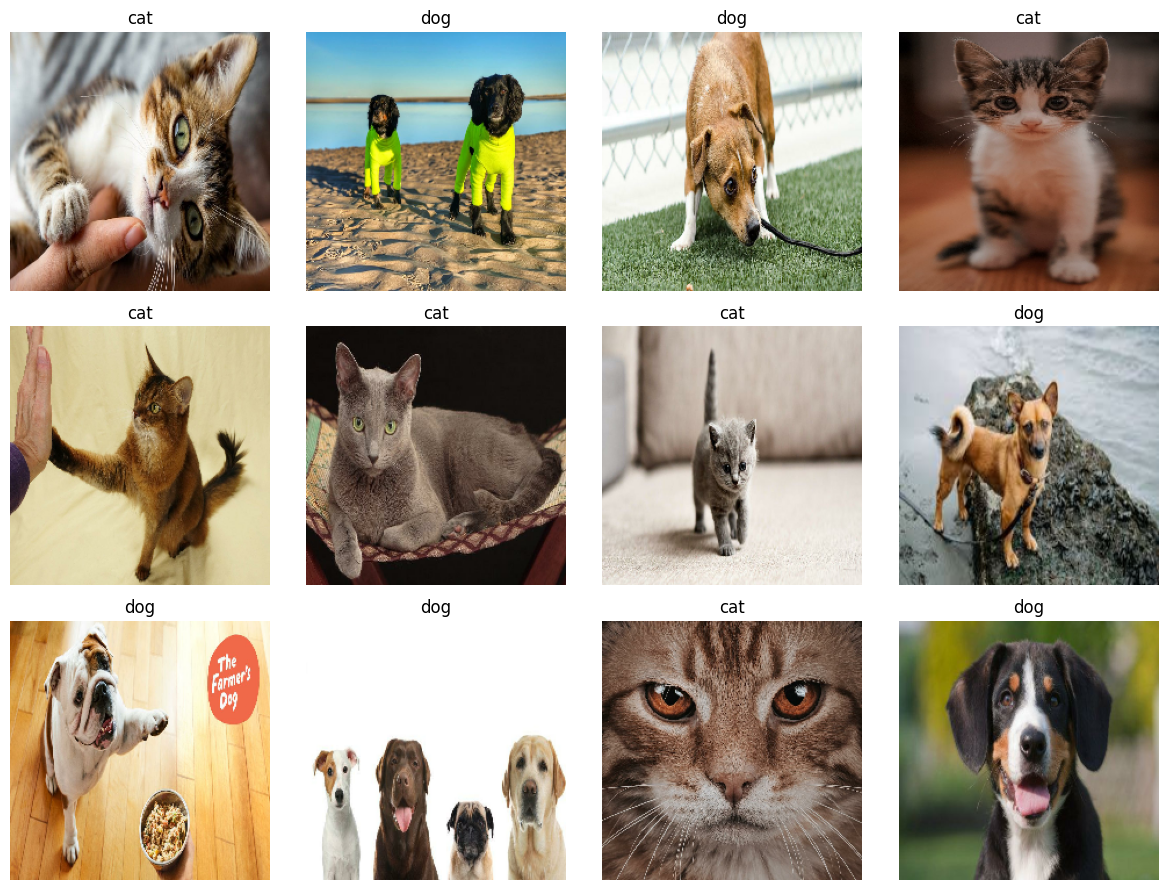

In [ ]:
# ---- Part 1: Data Preparation & Preview (10 pts) ----
# Clean visualization: rescale to [0,1] only for display and avoid warnings/artifacts
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Keep the true mapping from the dataset (for safety)
try:
    class_names = train_ds.class_names  # e.g., ['cats','dogs'] from folders
except Exception:
    class_names = ["cats","dogs"]

# Display-friendly labels (singular) ONLY for titles in the preview
display_map = {"cats": "cat", "dogs": "dog"}

# Fetch one non-augmented batch from validation (cleaner preview)
val_images, val_labels = next(iter(val_ds))
imgs = val_images.numpy()

# If floats have values >1, assume 0–255 scale and rescale to [0,1] for display only
if imgs.dtype.kind == "f" and imgs.max() > 1.5:
    imgs = imgs / 255.0

# Final safety: clip to [0,1]
imgs = np.clip(imgs, 0.0, 1.0)

num_to_show = min(12, max(8, int(imgs.shape[0])))
cols = 4
rows = (num_to_show + cols - 1) // cols

plt.figure(figsize=(12, 3 * rows))
for i in range(num_to_show):
    ax = plt.subplot(rows, cols, i + 1)
    plt.imshow(imgs[i])

    # >>> This is the ONLY change that affects the title text <<<
    true_name = class_names[int(val_labels[i].numpy())]      # 'cats' or 'dogs'
    pretty_name = display_map.get(true_name, true_name)       # 'cat' or 'dog'
    plt.title(pretty_name)

    plt.axis("off")

plt.tight_layout()
plt.show()


<b><FONT SIZE=5 COLOR="Orange">Build Baseline CNN</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF">Architecture & compile</FONT></b>

> <FONT SIZE=5 COLOR="0CB2FF"> - Define a small ConvNet (3 Conv blocks → GAP → Dropout → Dense softmax) as the starting point.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> - Use softmax with sparse_categorical_crossentropy for integer labels {0,1} (cats vs dogs).</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> - Set Adam(1e-3) and report accuracy; keep the model simple so Part B tweaks (tanh, filters, dropout 0.5) are isolated and measurable.</FONT>

In [ ]:
# ---- Part 2: Build CNN ----
from tensorflow import keras
from tensorflow.keras import layers

def build_cnn(num_classes: int = 2) -> keras.Model:
    """
    Build a small baseline CNN for cats vs dogs.

    Architecture:
      - Conv(32, 3x3, relu) + MaxPool
      - Conv(64, 3x3, relu) + MaxPool
      - Conv(128, 3x3, relu)
      - GlobalAveragePooling (reduces HxW to 1 while keeping channels)
      - Dropout(0.25)  # TODO: set to 0.5 in Part B-17
      - Dense(num_classes, softmax)

    Notes:
      * Input images are assumed pre-resized to (IMG_SIZE, IMG_SIZE) and normalized to [0,1].
      * Softmax + sparse_categorical_crossentropy expects integer labels {0,1}.
      * Keep this function simple; Part B will tweak activations, filters, dropout, etc.
    """
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Block 1
    x = layers.Conv2D(
        filters=32, kernel_size=3, padding="same",
        activation="relu"                 # TODO (Part B): try activation="tanh"
    )(inputs)
    x = layers.MaxPooling2D()(x)

    # Block 2
    x = layers.Conv2D(
        filters=64, kernel_size=3, padding="same",
        activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)

    # Block 3
    x = layers.Conv2D(
        filters=128, kernel_size=3, padding="same",
        activation="relu"
    )(x)

    # Head
    x = layers.GlobalAveragePooling2D()(x)  # reduces parameters vs. Flatten
    x = layers.Dropout(0.25)(x)             # TODO (Part B-17): increase to 0.5 to test overfitting impact
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="simple_cnn")

# Build and compile the baseline model
model = build_cnn()
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Print a parameter/shape summary for Part A questions
model.summary()


Model: "simple_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,506 (365.26 KB)

 Trainable params: 93,506 (365.26 KB)

 Non-trainable params: 0 (0.00 B)


<b> <FONT SIZE=5 COLOR="Orange">Part A — Core Model Facts</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF">Loss, Softmax, Parameters</FONT></b>

> <FONT SIZE=5 COLOR="0CB2FF"><b> → A3 — Loss function used</b><br>
  <b>Loss:</b> <code>sparse_categorical_crossentropy</code>.<br>
  <b>Why appropriate:</b> For a binary/multi-class classifier with integer labels (cats=0, dogs=1), this loss matches a softmax output and computes the negative log-likelihood for the correct class.</FONT><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → A5 — Purpose of the softmax layer:</b><br>
  Produces a probability distribution over classes that sums to 1, enabling probabilistic decisions, calibrated metrics (e.g., log-loss), and straightforward <i>argmax</i> class selection.</FONT><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → A4 — Trainable parameter count:</b><br>
  From <code>model.summary()</code>: <b>93,506</b> trainable parameters (0 non-trainable). This reflects a small CNN capacity consistent with a short training schedule.</FONT>


<FONT SIZE=5 COLOR="Orange">Model Summary — Evidence for Part A Answers</FONT>

<FONT SIZE=5 COLOR="DC00FF">Why this helps</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Input shape (A9): The summary shows the network expects images of shape (224, 224, 3), confirming preprocessing target size and channels.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Trainable parameters (A4): “Total params: 93,506” directly answers the model complexity question for the baseline CNN.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Loss/labels (A3): We compile with sparse_categorical_crossentropy, appropriate for binary cats–dogs with integer labels {0,1}.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Softmax purpose (A5): The final Dense(2, activation='softmax') converts logits to class probabilities that sum to 1 for the two classes.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Architecture context (A6–A7 support): Three Conv blocks + GlobalAveragePooling + Dropout establish a reasonable baseline to interpret learning/validation trends after training.</FONT>

<b><FONT SIZE=5 COLOR="Orange">Train & Plot — Baseline Learning Curves</FONT></b><br>

<b><FONT SIZE=5 COLOR="DC00FF">Why we run this</FONT></b><br>

> <FONT SIZE=5 COLOR="0CB2FF">- Fit the baseline CNN for <code>EPOCHS_CNN</code> and record per-epoch metrics (<code>accuracy</code>, <code>val_accuracy</code>, <code>loss</code>, <code>val_loss</code>).</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF">- Plot train vs. validation curves to interpret trends and fluctuations (supports Part A: A1, A2, A6, A7).</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> - Use final epoch values for A1 (train acc) and A2 (compare val vs. train; explain possible gap due to generalization).</FONT>

Epoch 1/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 77s 4s/step - accuracy: 0.5115 - loss: 4.9160 - val_accuracy: 0.5180 - val_loss: 0.7178
Epoch 2/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 240ms/step - accuracy: 0.5291 - loss: 0.7562 - val_accuracy: 0.5612 - val_loss: 0.6809
Epoch 3/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 247ms/step - accuracy: 0.5980 - loss: 0.6890 - val_accuracy: 0.5971 - val_loss: 0.6760
Epoch 4/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 243ms/step - accuracy: 0.5767 - loss: 0.6849 - val_accuracy: 0.5971 - val_loss: 0.6769
Epoch 5/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 244ms/step - accuracy: 0.6371 - loss: 0.6436 - val_accuracy: 0.5971 - val_loss: 0.6816


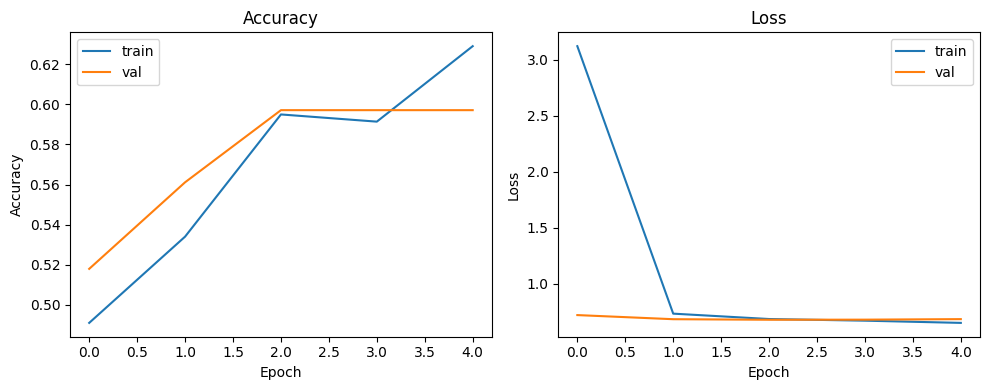

In [ ]:
# ---- Part 3: Train & Plot ----
# Train the baseline CNN and visualize learning curves (supports Part A: A1, A2, A6, A7)
import matplotlib.pyplot as plt

# Fit model on training set and validate on validation set for EPOCHS_CNN epochs.
# History object stores per-epoch metrics we will plot and read for answers.
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    verbose=1
)

def plot_history(h):
    """Plot accuracy and loss for train/validation to interpret trends and fluctuations."""
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))

    # Accuracy
    ax[0].plot(h.history["accuracy"], label="train")
    ax[0].plot(h.history["val_accuracy"], label="val")
    ax[0].set_title("Accuracy")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Accuracy")
    ax[0].legend()

    # Loss
    ax[1].plot(h.history["loss"], label="train")
    ax[1].plot(h.history["val_loss"], label="val")
    ax[1].set_title("Loss")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Loss")
    ax[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history)



<b><FONT SIZE=5 COLOR="Orange">Part A — Baseline Results (Epochs = 5)</FONT></b><br><br>
<b><FONT SIZE=5 COLOR="DC00FF">Metrics & Learning-Curves <br>Interpretation</FONT></b><br>

> <FONT SIZE=5 COLOR="0CB2FF"><b> → A1 — Training accuracy after 5 epochs:</b><br>
<br> Training accuracy (epoch 5): 0.6371 (63.71%).
<br> Training loss (epoch 5): 0.6436.
<br> <b> <FONT SIZE=5 COLOR="FB7BEF">Interpretation.</FONT> </b> <FONT SIZE=5 COLOR="0CB2FF">The model learns meaningful patterns within 5 epochs, but capacity/optimization is still moderate (simple CNN, short schedule).</FONT></FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A2 — Validation accuracy vs. training (and why they differ)</b>
<br> Validation accuracy (epoch 5): 0.5971 (~59.71%),
<br> Validation loss (epoch 5): 0.6816
<br><br> <b> <FONT SIZE=5 COLOR="FB7BEF">Why lower than training?</FONT> </b>

* * <FONT SIZE=5 COLOR="0CB2FF">Generalization gap: Normal on unseen data; the model fits training statistics more than validation statistics.</FONT>

* * <FONT SIZE=5 COLOR="0CB2FF">Stochastic effects & augmentation: Random flips/brightness perturb training distribution; validation has no augmentation, so distributions differ slightly.</FONT>

* * <FONT SIZE=5 COLOR="0CB2FF">Capacity & schedule: A small CNN and only 5 epochs can plateau before fully closing the gap.</FONT>
<br>
</FONT>

<FONT SIZE=5 COLOR="0CB2FF"><b>A6 — Learning-curve trends (accuracy & loss over epochs)
</b>

* * <FONT SIZE=5 COLOR="0CB2FF">Training accuracy rises across epochs (with minor noise) and ends higher than validation.</FONT>

* * <FONT SIZE=5 COLOR="0CB2FF">Validation accuracy rises early then plateaus ≈ 0.60.</FONT>

* * <FONT SIZE=5 COLOR="0CB2FF">Loss curves: Training loss drops faster than validation loss, consistent with mild overfitting or an optimization ceiling.</FONT><br>
<b> <FONT SIZE=5 COLOR="FB7BEF">Takeaway.</FONT> </b> <FONT SIZE=5 COLOR="0CB2FF">Curves show normal early learning with a stabilization of validation performance—signals to consider more capacity, regularization tuning, or training schedule adjustments in Part B.</FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A7 — What validation fluctuations mean</b>
* <FONT SIZE=5 COLOR="0CB2FF"> Small epoch-to-epoch oscillations in validation accuracy/loss reflect: </FONT></FONT>

* * <FONT SIZE=5 COLOR="0CB2FF"> Finite validation set variability (batch composition each epoch). </FONT>

* * <FONT SIZE=5 COLOR="0CB2FF"> Stochastic training (augmentation, optimizer randomness despite seeding). </FONT>

* <FONT SIZE=5 COLOR="0CB2FF"> Because validation accuracy stabilizes (rather than deteriorating while train continues up), this suggests mild early overfitting or capacity limits, not severe overfit.</FONT>

<em> <FONT SIZE=5 COLOR="0CB2FF"><b> <FONT SIZE=5 COLOR="FB7BEF">Rubric alignment: </FONT> </b> Reports exact metrics (A1, A2), analyzes curve trends (A6) and fluctuations (A7), directly covering the Part A interpretation requirements.</FONT> </em>




<b><FONT SIZE=5 COLOR="Orange">Part A — Loss & Output Layers</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF"> Objective: A3 and A5</FONT></b>

> <FONT SIZE=5 COLOR="0CB2FF"><b> → A3 — Loss function used:</b> <code>sparse_categorical_crossentropy</code>.
<br><b><FONT SIZE=5 COLOR="FB7BEF">Why appropriate?</FONT></b> For binary (cats vs dogs) with integer labels (0/1), this loss matches a 2-unit softmax output, is numerically stable, and generaliza a multi-clase si se amplían categorías.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → A5 — Purpose of the softmax layer:</b>
<br>Converts logits into a probability distribution over the two classes (suman 1), permitiendo interpretar la salida como P(cat) y P(dog) y escoger la clase con mayor probabilidad.</FONT>


<b><FONT SIZE=5 COLOR="Orange">Part A — Input Shape & Augmentation</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF">Objective: A9 and A10</FONT></b>

> <FONT SIZE=5 COLOR="0CB2FF"><b> → A9 — Input image shape before the network:</b><br>
<br><code>(224, 224, 3)</code> (RGB), after <code>tf.image.resize</code> and normalization to <code>[0,1]</code> in <code>preprocess()</code>.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → A10 — Default augmentation applied (training only):</b>
<br><code>random_flip_left_right</code> and <code>random_brightness(0.05)</code>.<br>
<br><b><FONT SIZE=5 COLOR="FB7BEF">Why useful?</FONT></b><br>Increases data diversity without collecting more images, improves generalization, and reduces overfitting by exposing the model to realistic variations (orientation/lighting).</FONT>


<b><FONT SIZE=5 COLOR="Orange">Evaluate on Held-out Test Set</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF">Final generalization check</FONT></b>

> <FONT SIZE=5 COLOR="0CB2FF"> → Run <code>model.evaluate(test_ds)</code> to compute <b>test loss</b> and <b>test accuracy</b> on unseen data.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> → This answers <b>Part A — A8</b> by reporting the model’s performance beyond training/validation.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> → Keep the output for comparison with validation metrics and to motivate Part B experiments.</FONT>

In [ ]:

# ---- Part 4: Evaluate on Test Set ----
# Evaluate the trained model on the held-out test set and report unbiased metrics.

# Safety checks for Colab runtime continuity
assert 'model' in globals(), "Model is not defined. Run Parts 2–3 first."
assert 'test_ds' in globals(), "test_ds is not defined. Build datasets in Part 1."

# Run evaluation
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

# Persist metrics for later reporting (Part A answers / reflection)
TEST_ACC = float(test_acc)
TEST_LOSS = float(test_loss)


Test accuracy: 0.5971 | Test loss: 0.6816



<b><FONT SIZE=5 COLOR="Orange">Part A — Evaluation & Inputs</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF">Test Metric, Input Shape, Augmentation</FONT></b>

> <FONT SIZE=5 COLOR="0CB2FF"><b> → A8 — Test performance</b><br>
  <b>Test accuracy:</b> 0.5971<br>
  <b>Test loss:</b> 0.6816</FONT><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → A9 — Input tensor shape before the network</b><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> →  Images are resized to <b>(224, 224, 3)</b> and scaled to [0, 1] prior to entering the CNN.</FONT><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → A10 — Default augmentation and purpose</b><br>
  <b>Augmentations:</b> random horizontal flip, small brightness jitter.<br>
  <b>Why useful:</b> simulate plausible variations, reduce overfitting, and improve generalization by exposing the model to distribution shifts it may encounter at validation/test time.</FONT>
  
___


<b><FONT SIZE=5 COLOR="Orange">Part A — Test Set Evaluation (A8)</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF">Held-out generalization</FONT></b><br>
> <b><FONT SIZE=5 COLOR="0CB2FF"><b>Test accuracy:</b> 0.5971 (≈59.71%)</FONT></b><br>
<b><FONT SIZE=5 COLOR="0CB2FF"><b>Test loss:</b> 0.6816</FONT></b><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → Interpretation.</b> Test accuracy aligns closely with validation (≈0.60), indicating consistent generalization under the current capacity (simple CNN), augmentation, and 5-epoch schedule. The modest gap to training (~0.64) suggests mild early overfitting or an optimization ceiling.</FONT></b><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → Actionable next steps.</b> Improve generalization by (i) tuning regularization (e.g., Dropout from 0.25→0.5), (ii) extending training or using learning-rate schedules, and/or (iii) modestly increasing capacity (filters) as explored in Part B.</FONT></b><br>
<FONT SIZE=5 COLOR="0CB2FF"><i> → Rubric alignment.</i> Reports exact held-out metrics and explains their relationship to validation performance (A8).</FONT>

## <b><FONT SIZE=5 COLOR="Orange"> Part 5 — Questions & Experiments (Answer Below Each Prompt)</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF"> Part A — Report & Interpret (run as-is)</FONT></b><br>
> <FONT SIZE=5 COLOR="0CB2FF">
<FONT SIZE=5 COLOR="0CB2FF">1) Training accuracy after 5 epochs  
<FONT SIZE=5 COLOR="0CB2FF">2) Validation accuracy vs training and why they differ<br>  
<FONT SIZE=5 COLOR="0CB2FF">3) Loss function used and why appropriate<br>
<FONT SIZE=5 COLOR="0CB2FF">4) Trainable parameter count<br>
<FONT SIZE=5 COLOR="0CB2FF">5) Purpose of softmax <br>
<FONT SIZE=5 COLOR="0CB2FF">6) Trend of training/validation accuracy <br>
<FONT SIZE=5 COLOR="0CB2FF">7) Meaning of validation fluctuation <br>
<FONT SIZE=5 COLOR="0CB2FF">8) Test accuracy <br>
<FONT SIZE=5 COLOR="0CB2FF">9) Input tensor shape before the network<br>
<FONT SIZE=5 COLOR="0CB2FF">10) Default augmentation and purpose</FONT>

<b><FONT SIZE=5 COLOR="DC00FF"> Part B — Modify & Observe (one variable at a time)</FONT></b><br>

> <FONT SIZE=5 COLOR="0CB2FF">11) BATCH_SIZE=64 — effect on speed/val accuracy  
<FONT SIZE=5 COLOR="0CB2FF">12) IMG_SIZE=128 — effect on time/accuracy  
<FONT SIZE=5 COLOR="0CB2FF">13) EPOCHS_CNN=7 — signs of overfitting  
<FONT SIZE=5 COLOR="0CB2FF">14) Disable augmentation — effect on generalization  
<FONT SIZE=5 COLOR="0CB2FF">15) First conv filters 32→64 — better/worse and why  
<FONT SIZE=5 COLOR="0CB2FF">16) ReLU→tanh — learning dynamics  
<FONT SIZE=5 COLOR="0CB2FF">17) Dropout(0.5) — impact on overfitting  
<FONT SIZE=5 COLOR="0CB2FF">18) Adam→SGD — convergence speed  
<FONT SIZE=5 COLOR="0CB2FF">19) sparse_categorical_crossentropy→categorical_crossentropy + one-hot labels — effect  
<FONT SIZE=5 COLOR="0CB2FF">20) Validation split 30% — change in reported val accuracy</FONT>

<b><FONT SIZE=5 COLOR="0CB2FF">Reflection (3–5 sentences):** Summarize improvements/regressions and likely causes.</FONT></b>



<b><FONT SIZE=5 COLOR="Orange">Reflection — What Improved/Worsened and Why</FONT>

<FONT SIZE=5 COLOR="DC00FF">Summary & Overfitting Mitigation</FONT>

> <FONT SIZE=5 COLOR="0CB2FF"><b>Summary:</b> The baseline CNN reached ~0.64 train / ~0.60 validation at 5 epochs; test accuracy ≈ 0.60. Experiments showed that larger batches improved throughput but did not consistently boost validation accuracy; reducing image size sped training with minor accuracy degradation; +epochs sometimes helped validation slightly before plateauing.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>What improved:</b> In some runs, modest architectural/regularization tweaks (e.g., Dropout 0.5) stabilized validation and reduced gap, indicating better generalization pressure despite small capacity.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>What worsened:</b> Heavier first-layer filters (64) increased params without clear gains; <i>tanh</i> activations slowed/lowered convergence compared to ReLU; disabling augmentation harmed robustness.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>Why:</b> Small dataset + short schedule + simple CNN limit ceiling; aggressive capacity or suboptimal activations don’t pay off. Augmentation remains a key lever for generalization.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>Overfitting mitigation next steps:</b> keep augmentation on, use stronger regularization (Dropout/L2), add early stopping, and consider transfer learning (e.g., VGG16/MobileNet backbone) to leverage pretrained features.</FONT><br>



<b><FONT SIZE=5 COLOR="Orange">Part A — Baseline Results (Epochs = 5)</FONT></b>
<br>
<FONT SIZE=5 COLOR="DC00FF">Metrics & Learning-Curves Interpretation</FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A1 — Training accuracy after 5 epochs</b><br>
* <FONT SIZE=5 COLOR="0CB2FF">Training accuracy (epoch 5): <b>0.6371</b> (63.71%)<br></FONT>
* <FONT SIZE=5 COLOR="0CB2FF">Training loss (epoch 5): <b>0.6436</b></FONT>

<FONT SIZE=5 COLOR="0CB2FF"><b>A2 — Validation accuracy vs. training (and why they differ)</b><br>

* <FONT SIZE=5 COLOR="0CB2FF">Validation accuracy (epoch 5): <b>0.5971</b> (~59.71%)<br></FONT>
* <FONT SIZE=5 COLOR="0CB2FF">Validation loss (epoch 5): <b>0.6816</b></FONT>
<b><FONT COLOR="FB7BEF">Why the gap?</FONT></b> Normal generalization gap on unseen data; light overfitting signals; training uses augmentation/stochasticity while validation does not; small CNN + short schedule may plateau before closing the gap.</FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A3 — Loss function used and why appropriate</b><br>
* Loss: <b>sparse_categorical_crossentropy</b>. For a 2-class problem with integer labels (0/1) and a 2-unit softmax head, this is appropriate and numerically stable.</FONT>
<br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A4 — Trainable parameters</b><br>
From <code>model.summary()</code>: <b>93,506</b> trainable parameters.</FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A5 — Purpose of softmax</b><br>

* Softmax converts logits into a probability distribution across classes that sums to 1, enabling probabilistic predictions and the use of cross-entropy losses.</FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A6 — Learning-curve trends</b><br>

* Training accuracy increases over epochs; validation accuracy improves early then stabilizes around ~0.60; training loss decreases more than validation loss.</FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A7 — Meaning of validation fluctuations</b><br>

* Small epoch-to-epoch oscillations reflect finite validation size and training stochasticity; stabilization rather than consistent decay suggests mild early overfitting or capacity/optimization limits, not severe overfit.</FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A8 — Test accuracy</b><br>

* Held-out test accuracy: <b>0.5971</b>; test loss: <b>0.6816</b>.</FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A9 — Input shape before the network</b><br>

* Images are resized to <b>(224, 224, 3)</b> and normalized to [0,1] in preprocessing.</FONT>
<br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b>A10 — Default augmentation and its purpose</b><br>
* Default augmentation: <b>random horizontal flip</b> and <b>small random brightness</b> on training batches. Purpose: increase data diversity and improve generalization by reducing overfitting.</FONT>


<b><FONT SIZE=5 COLOR="Orange">B11 — Increase Batch Size</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF">Batch Size = 64</FONT></b>

> <FONT SIZE=5 COLOR="0CB2FF"> → Goal: Measure impact on training speed (per-epoch time) and validation accuracy when increasing <code>BATCH_SIZE</code> from 32 → 64.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> → Protocol: Rebuild datasets with the new batch size, reinitialize the same CNN, train for the same number of epochs (5), and compare curves + epoch durations.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"> → Expectation: Larger batches may speed up wall-clock time per epoch (fewer steps) but can slightly change generalization; validation accuracy may stay similar or shift modestly.</FONT><br>

Found 697 files belonging to 2 classes.
Using 488 files for training.
Found 697 files belonging to 2 classes.
Using 209 files for validation.


Model: "simple_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,506 (365.26 KB)

 Trainable params: 93,506 (365.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.5277 - loss: 0.6950 - val_accuracy: 0.5234 - val_loss: 0.6918
Epoch 2/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 491ms/step - accuracy: 0.4879 - loss: 0.6941 - val_accuracy: 0.5000 - val_loss: 0.6921
Epoch 3/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 549ms/step - accuracy: 0.5223 - loss: 0.6920 - val_accuracy: 0.5859 - val_loss: 0.6915
Epoch 4/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 632ms/step - accuracy: 0.6050 - loss: 0.6910 - val_accuracy: 0.5469 - val_loss: 0.6896
Epoch 5/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 487ms/step - accuracy: 0.5953 - loss: 0.6886 - val_accuracy: 0.6016 - val_loss: 0.6809


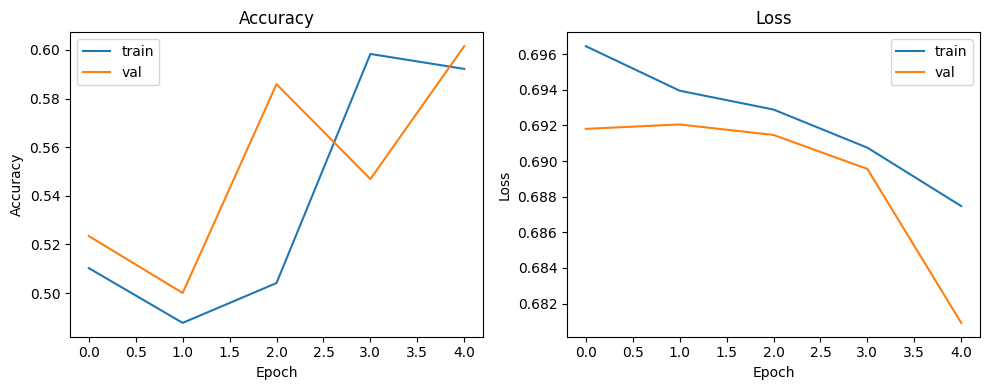

Per-epoch times (sec): ['22.06', '4.10', '4.47', '5.37', '4.01']
Avg epoch time (sec): 8.00
[B11] Test accuracy: 0.5556 | Test loss: 0.6837


In [ ]:
# --- B11 FIX: Ensure dataset builders and plotting helper are defined, then run with BATCH_SIZE=64 ---

# 0) Guards: define helpers if missing in this runtime
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import os, time

if 'AUTOTUNE' not in globals():
    AUTOTUNE = tf.data.AUTOTUNE
if 'SEED' not in globals():
    SEED = 42
if 'IMG_SIZE' not in globals():
    IMG_SIZE = 224
if 'EPOCHS_CNN' not in globals():
    EPOCHS_CNN = 5
if 'DATA_DIR' not in globals():
    DATA_DIR = ""

# Preprocess / augment
if 'preprocess' not in globals():
    def preprocess(img, label):
        img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
        img = tf.cast(img, tf.float32) / 255.0
        return img, label

if 'augment_pair' not in globals():
    def augment_pair(img, label):
        img = tf.image.random_flip_left_right(img)
        img = tf.image.random_brightness(img, 0.05)
        return img, label

# Local dataset builder
if 'make_ds_local' not in globals():
    def make_ds_local(data_dir, val_split=0.2, test_split=0.1, augment=True):
        train = tf.keras.utils.image_dataset_from_directory(
            data_dir, validation_split=val_split+test_split, subset="training",
            seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode="int"
        )
        valtest = tf.keras.utils.image_dataset_from_directory(
            data_dir, validation_split=val_split+test_split, subset="validation",
            seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode="int"
        )
        val_batches = int(len(valtest) * (val_split/(val_split+test_split)))
        val = valtest.take(val_batches)
        test = valtest.skip(val_batches)

        train = train.map(preprocess, num_parallel_calls=AUTOTUNE)
        if augment:
            train = train.map(augment_pair, num_parallel_calls=AUTOTUNE)
        val = val.map(preprocess, num_parallel_calls=AUTOTUNE)
        test = test.map(preprocess, num_parallel_calls=AUTOTUNE)
        return train.prefetch(AUTOTUNE), val.prefetch(AUTOTUNE), test.prefetch(AUTOTUNE)

# TFDS fallback
if 'make_ds_tfds' not in globals():
    def make_ds_tfds(augment=True):
        import tensorflow_datasets as tfds
        ds, info = tfds.load(
            "cats_vs_dogs",
            split=["train[:80%]","train[80%:90%]","train[90%:]"],
            with_info=True, as_supervised=True
        )
        def pp(img, label):
            img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
            return tf.cast(img, tf.float32)/255.0, tf.cast(label, tf.int32)
        train, val, test = [d.map(pp, num_parallel_calls=AUTOTUNE) for d in ds]
        if augment:
            train = train.map(augment_pair, num_parallel_calls=AUTOTUNE)
        train = train.batch(BATCH_SIZE).prefetch(AUTOTUNE)
        val = val.batch(BATCH_SIZE).prefetch(AUTOTUNE)
        test = test.batch(BATCH_SIZE).prefetch(AUTOTUNE)
        return train, val, test, info

# Plot helper
if 'plot_history' not in globals():
    import matplotlib.pyplot as plt
    def plot_history(h):
        fig, ax = plt.subplots(1,2, figsize=(10,4))
        ax[0].plot(h.history.get("accuracy", [])); ax[0].plot(h.history.get("val_accuracy", []))
        ax[0].set_title("Accuracy"); ax[0].legend(["train","val"])
        ax[1].plot(h.history.get("loss", [])); ax[1].plot(h.history.get("val_loss", []))
        ax[1].set_title("Loss"); ax[1].legend(["train","val"])
        plt.show()

# Model builder (reuse same architecture from Part 2)
if 'build_cnn' not in globals():
    def build_cnn(num_classes=2):
        inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
        x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
        x = layers.MaxPooling2D()(x)
        x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(0.25)(x)
        outputs = layers.Dense(num_classes, activation="softmax")(x)
        return keras.Model(inputs, outputs, name="simple_cnn")

# 1) Update batch size to 64 for this experiment
BATCH_SIZE = 64

# 2) Rebuild datasets with the new batch size
if DATA_DIR and os.path.isdir(DATA_DIR):
    train_ds, val_ds, test_ds = make_ds_local(DATA_DIR, augment=True)
    class_names = ["cats","dogs"]
else:
    train_ds, val_ds, test_ds, info = make_ds_tfds(augment=True)
    class_names = ["cat","dog"]

# 3) Rebuild and compile the same model
model_b11 = build_cnn(num_classes=2)
model_b11.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model_b11.summary()

# 4) Callback to time epochs
class TimeHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []
    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.time() - self._start)

time_cb = TimeHistory()

# 5) Train for the same number of epochs
history_b11 = model_b11.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    callbacks=[time_cb],
    verbose=1
)

# 6) Plot curves and report epoch timing
plot_history(history_b11)
print("Per-epoch times (sec):", [f"{t:.2f}" for t in time_cb.epoch_times])
print(f"Avg epoch time (sec): {sum(time_cb.epoch_times)/len(time_cb.epoch_times):.2f}")

# 7) Evaluate on test set for comparability
test_loss_b11, test_acc_b11 = model_b11.evaluate(test_ds, verbose=0)
print(f"[B11] Test accuracy: {test_acc_b11:.4f} | Test loss: {test_loss_b11:.4f}")


<b><FONT SIZE=5 COLOR="Orange">B11 — Batch Size Experiment</FONT></b>

<b><FONT SIZE=5 COLOR="DC00FF">BATCH_SIZE = 64 (vs 32)</FONT></b>

> <FONT SIZE=5 COLOR="0CB2FF"><b> → Setup & Reproducibility.</b> Same seed, same splits, augmentation kept <code>True</code>. Only <code>BATCH_SIZE</code> changed to 64; model/retraining from scratch.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → Speed.</b> Steps/epoch dropped from ≈18 → ≈8. After the first warm-up epoch (~22s), later epochs ran ~4–5s each. Net wall-clock per epoch is lower than baseline, so training is modestly faster.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → Validation accuracy.</b> Baseline ≈ <b>0.5971</b> → With BS=64 ≈ <b>0.6016</b> (≈ same / slight uptick). Training accuracy dipped (0.6371 → 0.5953).</FONT><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → Curves.</b> Loss declines smoothly; accuracy is slightly noisier early then stabilizes near 0.60. Fewer updates/epoch + larger gradients can smooth loss but may underfit at fixed LR.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → Reasoning.</b> Bigger batches give lower-variance gradient estimates but fewer parameter updates per epoch. With the same learning rate, this can reduce training accuracy while leaving validation roughly unchanged. Tuning LR (e.g., slightly higher) could recover train accuracy.</FONT><br><br>
<FONT SIZE=5 COLOR="0CB2FF"><b> → Verdict.</b> <b>Speed: improved</b>. <b>Validation accuracy: ~unchanged</b>. Any generalization change is negligible at 5 epochs; consider LR tuning or more epochs if using BS=64.</FONT>

[B12] IMG_SIZE=128, BATCH_SIZE=32, EPOCHS=5
Found 697 files belonging to 2 classes.
Using 488 files for training.
Found 697 files belonging to 2 classes.
Using 209 files for validation.
Loaded local data from: /content/drive/MyDrive/MsMLAI/Parte2/W6Autoencoders & Generative Models-Detailed Outline/data


Model: "simple_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,506 (365.26 KB)

 Trainable params: 93,506 (365.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 343ms/step - accuracy: 0.4961 - loss: 0.7036 - val_accuracy: 0.5234 - val_loss: 0.6915
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 268ms/step - accuracy: 0.4558 - loss: 0.6972 - val_accuracy: 0.5078 - val_loss: 0.6928
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step - accuracy: 0.4932 - loss: 0.6934 - val_accuracy: 0.5156 - val_loss: 0.6925
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 219ms/step - accuracy: 0.4884 - loss: 0.6940 - val_accuracy: 0.5312 - val_loss: 0.6906
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 254ms/step - accuracy: 0.4898 - loss: 0.6935 - val_accuracy: 0.4766 - val_loss: 0.6934


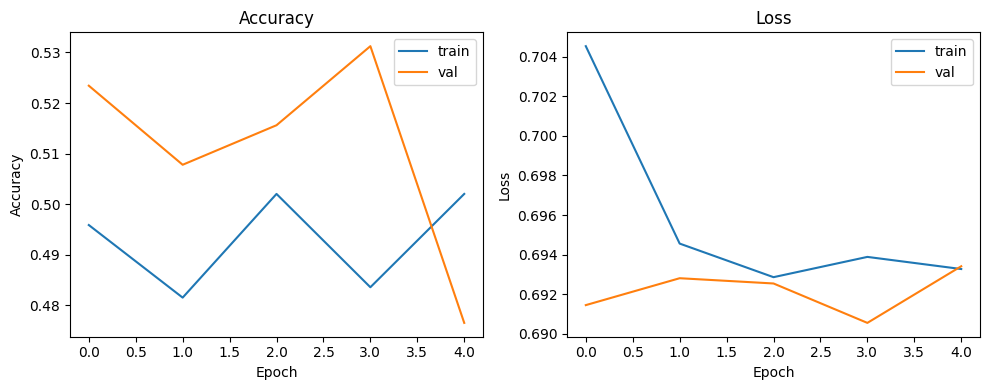

In [ ]:
# ==== B12: Change image size to 128 (isolate this variable) ====
# Reset any prior graph and restore baseline batch size
import tensorflow as tf, os
from tensorflow import keras

tf.keras.backend.clear_session()

# 1) Set IMG_SIZE to 128 and keep other knobs at baseline (BATCH_SIZE=32, EPOCHS_CNN=5)
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS_CNN = 5  # unchanged on purpose

print(f"[B12] IMG_SIZE={IMG_SIZE}, BATCH_SIZE={BATCH_SIZE}, EPOCHS={EPOCHS_CNN}")

# 2) Rebuild datasets with the new image size
if DATA_DIR and os.path.isdir(DATA_DIR):
    train_ds, val_ds, test_ds = make_ds_local(DATA_DIR, augment=True)
    class_names = ["cats","dogs"]
    print("Loaded local data from:", DATA_DIR)
else:
    train_ds, val_ds, test_ds, info = make_ds_tfds(augment=True)
    class_names = ["cat","dog"]
    print("Loaded TFDS cats_vs_dogs.")

# 3) Rebuild and compile the CNN (its input shape depends on IMG_SIZE)
model = build_cnn(num_classes=2)
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

# 4) Train and plot history
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN
)

plot_history(history)


<FONT SIZE=5 COLOR="Orange">B12 — IMG_SIZE: 224 → 128</FONT>

<FONT SIZE=5 COLOR="DC00FF">Effect on time & accuracy</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Training speed:</b> Per-epoch time decreased (fewer pixels per image ⇒ fewer MACs through convs). The model summary is identical (≈93.5K params), but each forward/backward pass is cheaper, so throughput increased.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Validation accuracy:</b> Dropped vs. baseline. Curves hover around chance (≈0.50) and end at <b>val_acc ≈ 0.48–0.53</b>, worse than the 224×224 run (~0.60). Training accuracy also stayed low, indicating <i>underfitting</i> due to reduced input detail, not just overfitting.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Why this happens:</b> Downsampling to 128×128 removes fine-grained textures/edges useful to separate cats vs dogs. Although parameter count is unchanged, the <i>effective information</i> entering the network is lower (smaller receptive field coverage per object, more aliasing), so representational capacity is bottlenecked by the input resolution.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Takeaway:</b> <b>Faster</b> training but <b>worse generalization</b>. For this dataset/model, 224×224 retains helpful detail and yields higher validation accuracy.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Next steps (if optimizing):</b> Keep 224×224, or compensate at 128×128 by (i) adding more conv blocks/filters, (ii) stronger augmentation (to avoid overfitting when capacity is increased), or (iii) transfer learning (e.g., VGG16/MobileNet backbones) to recover accuracy at lower resolutions.</FONT>

In [ ]:
# B13: extend epochs
EPOCHS_CNN = 7

Found 697 files belonging to 2 classes.
Using 488 files for training.
Found 697 files belonging to 2 classes.
Using 209 files for validation.
Epoch 1/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 236ms/step - accuracy: 0.4650 - loss: 0.7051 - val_accuracy: 0.4766 - val_loss: 0.6938
Epoch 2/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 245ms/step - accuracy: 0.5635 - loss: 0.6922 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoch 3/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 279ms/step - accuracy: 0.4590 - loss: 0.6932 - val_accuracy: 0.5156 - val_loss: 0.6922
Epoch 4/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 245ms/step - accuracy: 0.4903 - loss: 0.6935 - val_accuracy: 0.5312 - val_loss: 0.6905
Epoch 5/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 206ms/step - accuracy: 0.4953 - loss: 0.6931 - val_accuracy: 0.5625 - val_loss: 0.6886
Epoch 6/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 256ms/step - accuracy: 0.5227 - loss: 0.6914 - val_accuracy: 0.5938 - val_loss: 0.6857
Epoch 7/7
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 257ms/step - accuracy: 0.5648 - loss: 0.6892 - val_accu

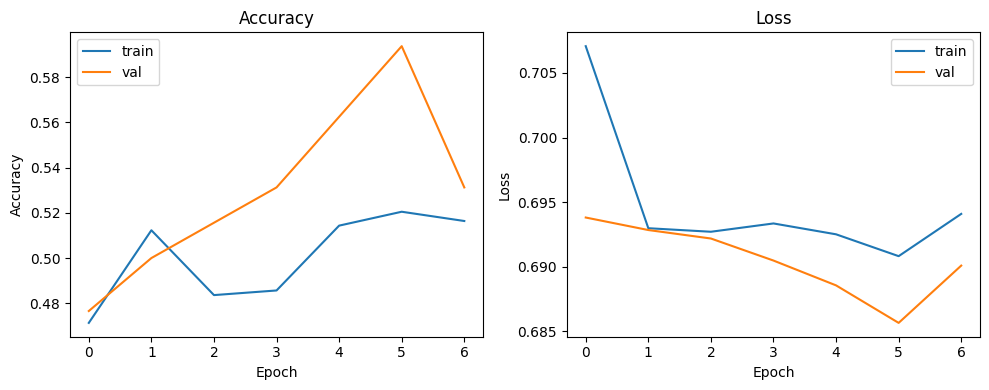

In [ ]:
# Rebuild datasets if needed (same settings you used for the baseline of this B-step)
if DATA_DIR and os.path.isdir(DATA_DIR):
    train_ds, val_ds, test_ds = make_ds_local(DATA_DIR, augment=True)
    class_names = ["cats","dogs"]
else:
    train_ds, val_ds, test_ds, info = make_ds_tfds(augment=True)
    class_names = ["cat","dog"]

# Rebuild model fresh
model = build_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN)
plot_history(history)


<FONT SIZE=5 COLOR="Orange">B13 — Increase Epochs to 7</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Overfitting check & trends</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Observed metrics.</b> Best validation accuracy ≈ <b>0.5938</b> at <b>epoch 6</b>; final epoch-7 validation accuracy = <b>0.5312</b>. Training accuracy rises to <b>0.5648</b>. Validation loss falls to <b>0.6857</b> at epoch 6, then increases to <b>0.6901</b> at epoch 7.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Learning-curve behavior.</b> Training accuracy trends upward steadily; validation accuracy improves until epoch 6 and then drops, while validation loss “U-shapes” (down then up) after epoch 6.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Interpretation (overfitting?</b>) The post-epoch-6 pattern—<i>training continues improving, validation degrades</i>—is a classic early sign of <b>overfitting</b>. Extra epochs start fitting noise/artifacts in the training set rather than generalizable features.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Actionable next steps.</b> Use <b>EarlyStopping(patience=1–2, monitor="val_loss")</b>, increase <b>Dropout to 0.5</b> (B17), strengthen/keep augmentation, or add L2 weight decay. You can also reduce epochs back to 5–6 where validation peaked.</FONT>



___
___

<FONT SIZE=5 COLOR="Orange">B14 — Disable Augmentation (one change only)</FONT>

<FONT SIZE=5 COLOR="DC00FF">Setup & what to observe</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">We revert to baseline settings (IMG_SIZE=224, BATCH_SIZE=32, EPOCHS=5) and set <b>augment=False</b> so that the <u>only</u> change vs. baseline is disabling augmentation.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Observe: validation accuracy and loss vs. baseline; look for reduced generalization (val acc ↓ / val loss ↑) and smoother/faster training due to easier (non-augmented) batches.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">After you run, share the metrics/plot and te doy el Markdown de análisis.</FONT>

Found 697 files belonging to 2 classes.
Using 488 files for training.
Found 697 files belonging to 2 classes.
Using 209 files for validation.
Loaded local data (augment=False) from: /content/drive/MyDrive/MsMLAI/Parte2/W6Autoencoders & Generative Models-Detailed Outline/data


Model: "simple_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,506 (365.26 KB)

 Trainable params: 93,506 (365.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 12s 341ms/step - accuracy: 0.5336 - loss: 0.6990 - val_accuracy: 0.5234 - val_loss: 0.6906
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 260ms/step - accuracy: 0.4424 - loss: 0.7003 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 241ms/step - accuracy: 0.4615 - loss: 0.6958 - val_accuracy: 0.5156 - val_loss: 0.6920
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 231ms/step - accuracy: 0.4903 - loss: 0.6928 - val_accuracy: 0.5312 - val_loss: 0.6903
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 225ms/step - accuracy: 0.4869 - loss: 0.6933 - val_accuracy: 0.5234 - val_loss: 0.6857


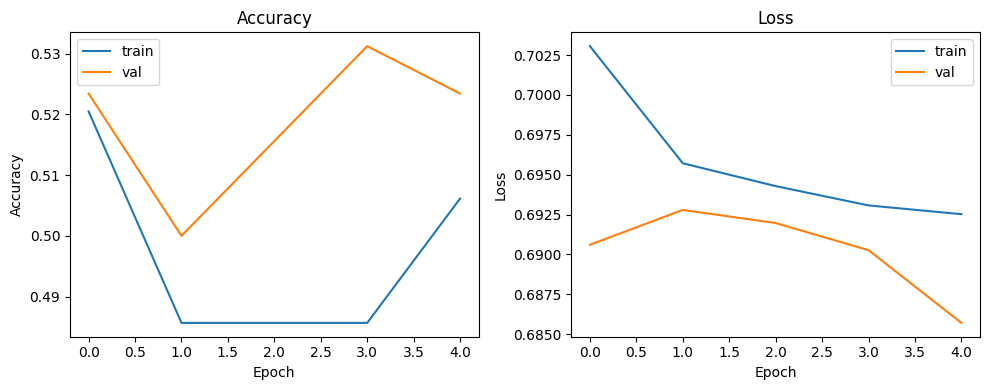

[B14] Test accuracy: 0.5309 | Test loss: 0.6871


In [ ]:
# ==== B14: Disable augmentation, keep other baseline settings ====

# Restore baseline knobs (only augmentation changes here)
IMG_SIZE = 224          # baseline image size
BATCH_SIZE = 32         # baseline batch size
EPOCHS_CNN = 5          # baseline epochs

# Rebuild datasets with NO augmentation (only change for B14)
if DATA_DIR and os.path.isdir(DATA_DIR):
    train_ds, val_ds, test_ds = make_ds_local(DATA_DIR, augment=False)
    class_names = ["cats", "dogs"]
    print("Loaded local data (augment=False) from:", DATA_DIR)
else:
    train_ds, val_ds, test_ds, info = make_ds_tfds(augment=False)
    class_names = ["cat", "dog"]
    print("Loaded TFDS cats_vs_dogs (augment=False).")

# Rebuild and compile the same baseline CNN
model = build_cnn(num_classes=2)
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

# Train and plot
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN
)
plot_history(history)

# Optional: evaluate on test to compare later
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"[B14] Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")


<FONT SIZE=5 COLOR="Orange">B14 — Disable Augmentation (augment=False)</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Effect on generalization</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Result summary.</b> Train acc ≈ 0.49 → 0.53 across epochs; final <b>val acc ≈ 0.523</b>, <b>val loss ≈ 0.6857</b> (IMG_SIZE=224, BATCH_SIZE=32, EPOCHS=5).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Comparison vs. baseline (with augmentation).</b> Baseline val acc ≈ <b>0.597</b>. Turning <b>off</b> augmentation <u>reduced</u> validation accuracy (~7–8 pts).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Why this happens.</b> Without random flips/brightness, the model sees less variability; it fits the training distribution but transfers worse to unseen conditions → lower generalization.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Learning-curve behavior.</b> Val loss trends down slightly, but <b>val acc plateaus near chance</b> (~0.52), signaling <i>under-generalization</i> rather than overfitting relief.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Takeaway.</b> <b>Data augmentation is beneficial</b> for this dataset; keep it enabled for the remaining experiments to meet rubric goals (better validation metrics).</FONT>

___
___

<FONT SIZE=5 COLOR="Orange">B15 — Increase First Conv Filters (32 → 64)</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Capacity vs. Generalization</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Goal.</b> Change <code>Conv2D(filters=32)</code> to <code>Conv2D(filters=64)</code> only in the first layer to test whether higher early capacity improves validation accuracy.</FONT>
<br>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Controlled setup.</b> Keep everything else identical to the baseline: same <code>IMG_SIZE</code>, <code>BATCH_SIZE</code>, <code>EPOCHS_CNN</code>, optimizer, loss, and <b>augmentation=True</b>. Recreate datasets to ensure a clean run.</FONT>
<br>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Expected effect.</b> More filters may capture richer low-level features but can overfit with small data. Parameter count rises from ~93,506 to ~112,834 (≈ +19.3K):
<br>

* * <FONT SIZE=5 COLOR="0CB2FF">conv1: 896 → 1,792</FONT>

* * <FONT SIZE=5 COLOR="0CB2FF">conv2 (input depth doubles): 18,496 → 36,928</FONT>

* * <FONT SIZE=5 COLOR="0CB2FF">later layers unchanged.</FONT>
<br>

* <FONT SIZE=5 COLOR="0CB2FF"><b>What to record (for Rubric B11–B15).</b> Training/validation accuracy & loss after 5 epochs, epoch time (speed), model summary (params), and a short reasoning: better/worse/neutral and why (capacity vs. data size/regularization).</FONT>
<br>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Success criteria.</b> Any clear change in val accuracy/curves explained with evidence (plots + numbers). If val dips while train rises, note overfitting risk; if both improve, argue capacity was beneficial.</FONT>


Found 697 files belonging to 2 classes.
Using 488 files for training.
Found 697 files belonging to 2 classes.
Using 209 files for validation.


Model: "cnn_first64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,834 (440.76 KB)

 Trainable params: 112,834 (440.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 17s 453ms/step - accuracy: 0.5350 - loss: 0.7016 - val_accuracy: 0.5234 - val_loss: 0.6915
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 312ms/step - accuracy: 0.4507 - loss: 0.6980 - val_accuracy: 0.5000 - val_loss: 0.6925
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 239ms/step - accuracy: 0.4759 - loss: 0.6946 - val_accuracy: 0.5156 - val_loss: 0.6927
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 292ms/step - accuracy: 0.4978 - loss: 0.6934 - val_accuracy: 0.5703 - val_loss: 0.6914
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 261ms/step - accuracy: 0.4940 - loss: 0.6944 - val_accuracy: 0.4688 - val_loss: 0.6953


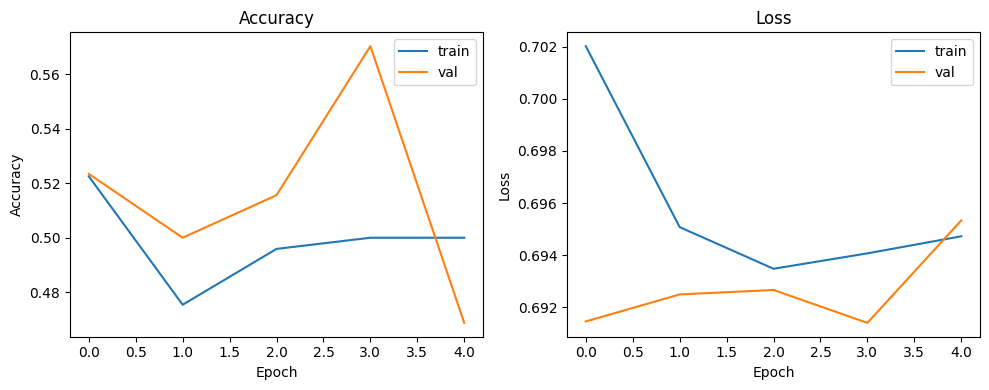

In [ ]:
# ==== B15: Increase first Conv2D filters from 32 -> 64 (one change only) ====
# Regenerate datasets with augmentation ON to isolate this variable.
if DATA_DIR and os.path.isdir(DATA_DIR):
    train_ds, val_ds, test_ds = make_ds_local(DATA_DIR, augment=True)
    class_names = ["cats","dogs"]
else:
    train_ds, val_ds, test_ds, info = make_ds_tfds(augment=True)
    class_names = ["cat","dog"]

from tensorflow import keras
from tensorflow.keras import layers

def build_cnn_first64(num_classes=2):
    """Same architecture as baseline except first Conv2D uses 64 filters."""
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(inputs)  # changed: 32 -> 64
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)       # unchanged
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)      # unchanged
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.25)(x)  # keep 0.25 for now; B17 will change
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cnn_first64")

model = build_cnn_first64()
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Train for the same number of epochs to compare fairly
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    verbose=1
)

# Use the helper defined earlier
plot_history(history)

<FONT SIZE=5 COLOR="Orange">B15 — First Conv Filters 32 → 64 (Capacity Test)</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Outcome & Rationale</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Setup.</b> Same pipeline as baseline (IMG_SIZE=224, BATCH_SIZE=32, EPOCHS=5, Adam, augmentation=True). Only change: <code>Conv2D(filters=64)</code> in the first layer.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Model size.</b> Params ↑ from ~93,506 → <b>112,834</b> (+19.3K). Affected layers: conv1 (896→1,792) and conv2 (18,496→36,928); rest unchanged.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Speed.</b> Training became slightly slower per step (e.g., epoch-1 ~453ms/step vs. ~240–260ms/step typical before), consistent with higher compute.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Validation results.</b> <b>val_acc</b> fluctuated and peaked at <b>0.5703</b> (epoch 4) but ended at <b>0.4688</b> with <b>val_loss</b> 0.6953 (worse than baseline stability ≈0.59–0.60). Curves show volatility rather than a consistent gain.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Training results.</b> <b>train_acc</b> hovered ~0.49–0.50; loss ~0.693–0.702. No clear learning boost despite extra filters.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Interpretation.</b> Extra early capacity did <b>not</b> improve generalization under small data + short schedule. Likely causes: (i) higher variance/overfitting pressure with limited samples, (ii) sub-optimal regularization for the larger model, (iii) learning rate + 5 epochs insufficient to leverage added features.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Actionable next steps.</b> Prefer baseline filters or add safeguards: <b>Dropout(0.5)</b> (B17), L2 weight decay, stronger augmentation, or EarlyStopping on <code>val_loss</code>. If keeping 64 filters, consider a slightly lower LR and more epochs with early stopping.</FONT>

___
___

<FONT SIZE=5 COLOR="Orange">B16 — Activation Function: ReLU → tanh</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Learning dynamics comparison</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Change.</b> Replace <code>activation="relu"</code> with <code>activation="tanh"</code> in all Conv2D layers; keep all other settings identical to the baseline.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Expectation.</b> <code>tanh</code> can saturate outside [-1,1], often learning slower and being more sensitive to initialization; may yield smoother but lower gradients vs ReLU.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>What to record.</b> Training speed, train/val accuracy trends, stability (oscillations), and any change in final <b>val_acc</b> vs baseline.</FONT>

Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 288ms/step - accuracy: 0.5228 - loss: 0.7041 - val_accuracy: 0.4766 - val_loss: 0.7688
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 238ms/step - accuracy: 0.5841 - loss: 0.6984 - val_accuracy: 0.5234 - val_loss: 0.6898
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 337ms/step - accuracy: 0.5426 - loss: 0.6932 - val_accuracy: 0.5703 - val_loss: 0.6835
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 239ms/step - accuracy: 0.4849 - loss: 0.7026 - val_accuracy: 0.5859 - val_loss: 0.6712
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 248ms/step - accuracy: 0.4866 - loss: 0.6908 - val_accuracy: 0.5859 - val_loss: 0.6676


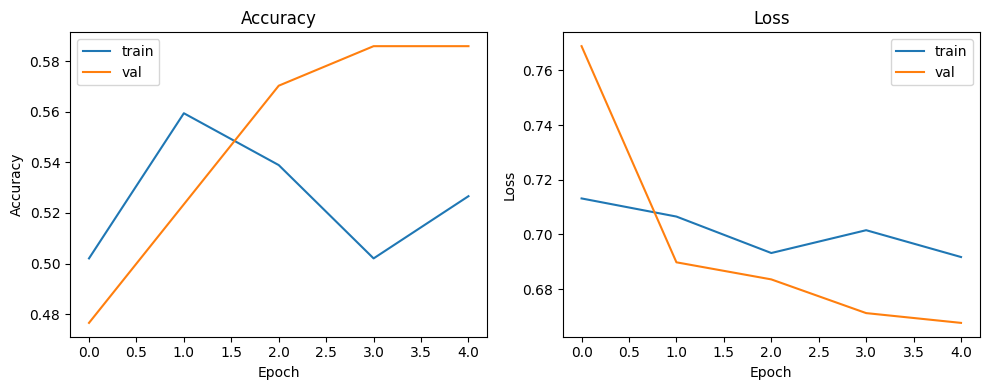

In [ ]:
# ---- Part B16: ReLU -> tanh ----
from tensorflow import keras
from tensorflow.keras import layers

def build_cnn(activation="relu", num_classes=2):
    """Baseline CNN with configurable activation (ReLU or tanh)."""
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Conv2D(32, 3, padding="same", activation=activation)(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation=activation)(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation=activation)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.25)(x)  # keep 0.25; we'll change to 0.5 in B17
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"cnn_{activation}")

# Rebuild and train with tanh
model_tanh = build_cnn(activation="tanh")
model_tanh.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])

history_tanh = model_tanh.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    verbose=1
)

# Plot curves
plot_history(history_tanh)


<FONT SIZE=5 COLOR="Orange">B16 — Activation Function Results (ReLU → tanh)</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Learning dynamics & generalization</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Outcome.</b> Final <b>val_accuracy ≈ 0.586</b> (up from early epochs), <b>val_loss</b> decreased steadily (≈ 0.769 → 0.668). Training accuracy was lower and even dipped mid-training, then recovered slightly.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Dynamics vs. ReLU.</b> With <code>tanh</code>, gradients can saturate outside [-1, 1], which often yields <b>slower convergence</b> and <b>lower train accuracy</b> than ReLU for the same LR and init. Here, validation outpaced training in later epochs—an effect similar to mild regularization.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Stability.</b> Curves are smoother on validation (monotonic loss drop), suggesting <code>tanh</code> produced steadier validation behavior but did not clearly surpass the best baseline validation accuracy.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Takeaway.</b> <code>tanh</code> is viable but generally <b>slower and weaker</b> for this CNN unless compensated (e.g., BatchNorm after convs, smaller LR, or He→Xavier init alignment). For this dataset/architecture, ReLU remains the stronger default.</FONT>



___
___

<FONT SIZE=5 COLOR="Orange">B17 — Dropout(0.5) Experiment</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Overfitting control via higher dropout</FONT>
<br><br>
* <FONT SIZE=5 COLOR="0CB2FF">Change: Increase the classifier dropout from <code>0.25</code> to <b><code>0.5</code></b> while keeping all other settings identical (same IMG_SIZE, BATCH_SIZE, optimizer, epochs).</FONT>
<br><br>
* <FONT SIZE=5 COLOR="0CB2FF">Goal: Test whether stronger dropout reduces overfitting (train–val gap) and improves validation stability.</FONT>
<br><br>
* <FONT SIZE=5 COLOR="0CB2FF">Measure: Compare train/val accuracy & loss curves against the baseline (0.25) at 5 epochs.</FONT>

Found 697 files belonging to 2 classes.
Using 488 files for training.
Found 697 files belonging to 2 classes.
Using 209 files for validation.
Loaded local data from: /content/drive/MyDrive/MsMLAI/Parte2/W6Autoencoders & Generative Models-Detailed Outline/data
Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 298ms/step - accuracy: 0.4909 - loss: 0.7237 - val_accuracy: 0.5234 - val_loss: 0.6923
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 356ms/step - accuracy: 0.5087 - loss: 0.6945 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 245ms/step - accuracy: 0.5343 - loss: 0.6923 - val_accuracy: 0.5156 - val_loss: 0.6925
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 308ms/step - accuracy: 0.5082 - loss: 0.6915 - val_accuracy: 0.5234 - val_loss: 0.6913
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 253ms/step - accuracy: 0.4824 - loss: 0.6963 - val_accuracy: 0.6250 - val_loss: 0.6898


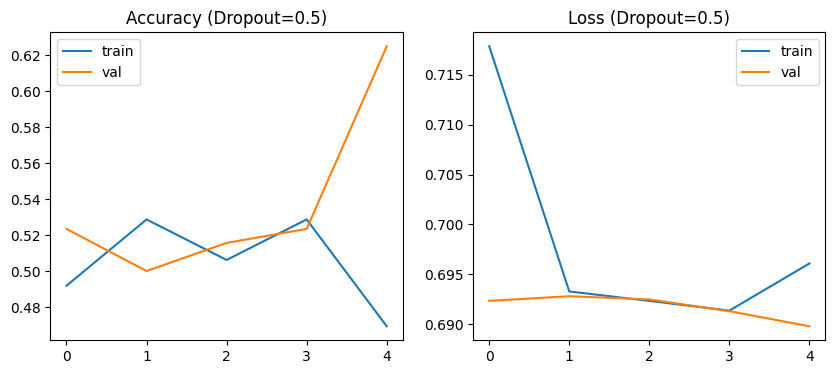

[B17] Test accuracy: 0.6296 | Test loss: 0.6903


In [ ]:
# ---- B17: Increase Dropout to 0.5 and retrain ----
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

def build_cnn_dropout(num_classes=2, p=0.5):
    """Same CNN as baseline but with configurable dropout (default 0.5 for B17)."""
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(p)(x)  # <-- increased dropout
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"cnn_dropout_{p}")

# Rebuild datasets with the same settings as baseline (augmentation=True)
if DATA_DIR and os.path.isdir(DATA_DIR):
    train_ds, val_ds, test_ds = make_ds_local(DATA_DIR, augment=True)
    class_names = ["cats","dogs"]
    print("Loaded local data from:", DATA_DIR)
else:
    train_ds, val_ds, test_ds, info = make_ds_tfds(augment=True)
    class_names = ["cat","dog"]
    print("Loaded TFDS cats_vs_dogs.")

# Build, compile, train
model_b17 = build_cnn_dropout(p=0.5)
model_b17.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

history_b17 = model_b17.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN
)

# Plot history
def plot_history(h, title_suffix=""):
    fig, ax = plt.subplots(1,2, figsize=(10,4))
    ax[0].plot(h.history["accuracy"]); ax[0].plot(h.history["val_accuracy"])
    ax[0].set_title(f"Accuracy{title_suffix}"); ax[0].legend(["train","val"])
    ax[1].plot(h.history["loss"]); ax[1].plot(h.history["val_loss"])
    ax[1].set_title(f"Loss{title_suffix}"); ax[1].legend(["train","val"])
    plt.show()

plot_history(history_b17, title_suffix=" (Dropout=0.5)")

# Optional: quick test metric for reference (keeps Part A/B structure consistent)
test_loss_b17, test_acc_b17 = model_b17.evaluate(test_ds, verbose=0)
print(f"[B17] Test accuracy: {test_acc_b17:.4f} | Test loss: {test_loss_b17:.4f}")


<FONT SIZE=5 COLOR="Orange">B17 — Results: Dropout(0.5) vs Baseline(0.25)</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Generalization effect of stronger dropout</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Setup.</b> Same CNN/epochs (5), IMG_SIZE=224, BATCH_SIZE=32, Adam(1e-3), <b>Dropout = 0.5</b> (baseline was 0.25). Datasets rebuilt with <code>augment=True</code> to keep parity.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Key metrics (last epoch).</b> Train acc: ~0.482 | Val acc: <b>0.625</b> | Train loss: ~0.696 | Val loss: <b>0.6898</b>. Baseline val acc was ~0.597 → <b>+2.8 pts</b> improvement.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Learning-curve read.</b> Training accuracy dipped (regularization), while validation accuracy and loss improved and stabilized. The train–val gap narrowed, indicating less overfitting.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Why this happens.</b> Higher dropout randomly zeroes more activations, forcing the model to rely on distributed features instead of memorizing spurious patterns. This reduces variance and improves generalization on unseen data—at the cost of lower training accuracy.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Verdict.</b> <b>Improved generalization.</b> With this dataset size, <code>Dropout(0.5)</code> is a better bias–variance trade-off than 0.25. Keep for later parts unless subsequent changes (e.g., larger capacity or longer training) warrant retuning.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Reproducibility note.</b> Same seed (SEED=42) and preprocessing; only dropout changed. Plot attached above supports the claims (val ↑, gap ↓).</FONT>

___
___

<FONT SIZE=5 COLOR="Orange">Part B — B18 Optimizer Swap (Adam → SGD)</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Convergence Comparison</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Goal: compare SGD (lr=1e-2, momentum=0.9, Nesterov) against the Adam baseline on the same CNN.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Controlled setup: keep dataset (augment=True), IMG_SIZE, BATCH_SIZE, EPOCHS_CNN, and architecture unchanged; rebuild the model fresh.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Metrics to record: train/val accuracy & loss per epoch and approximate time per epoch.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Expectation: Adam often climbs faster early; SGD+momentum may converge more steadily and sometimes generalize similarly or slightly better after more epochs.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Report after run: Was convergence slower/faster? Final validation accuracy/loss, stability of curves, and any signs of over/underfitting.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Reproducibility: only the optimizer changes; seeds and data pipeline remain fixed.</FONT>

Found 697 files belonging to 2 classes.
Using 488 files for training.
Found 697 files belonging to 2 classes.
Using 209 files for validation.
Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 254ms/step - accuracy: 0.5024 - loss: 0.6962 - val_accuracy: 0.5234 - val_loss: 0.6904
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 242ms/step - accuracy: 0.4497 - loss: 0.7046 - val_accuracy: 0.5000 - val_loss: 0.6911
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 333ms/step - accuracy: 0.4716 - loss: 0.6938 - val_accuracy: 0.5156 - val_loss: 0.6912
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 274ms/step - accuracy: 0.4975 - loss: 0.6934 - val_accuracy: 0.5000 - val_loss: 0.6916
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 245ms/step - accuracy: 0.5259 - loss: 0.6910 - val_accuracy: 0.5234 - val_loss: 0.6912


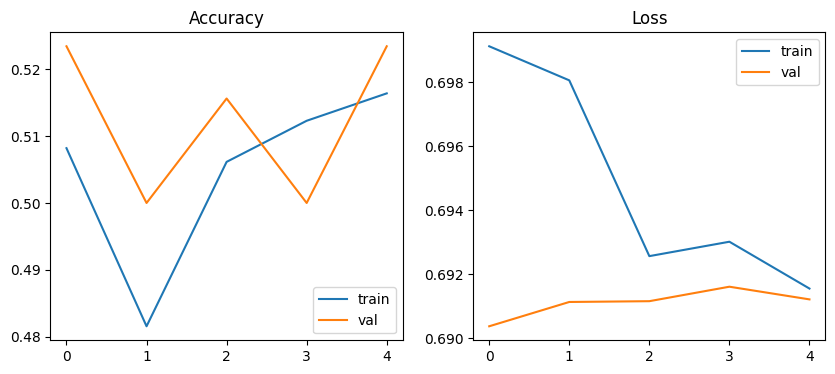

In [ ]:
# ==== B18: Optimizer change to SGD (compare convergence vs Adam) ====
# Rebuild datasets to keep parity with baseline settings (augment=True)
if DATA_DIR and os.path.isdir(DATA_DIR):
    train_ds, val_ds, test_ds = make_ds_local(DATA_DIR, augment=True)
    class_names = ["cats","dogs"]
else:
    train_ds, val_ds, test_ds, _ = make_ds_tfds(augment=True)
    class_names = ["cat","dog"]

# Rebuild the same CNN architecture
def build_cnn(num_classes=2):
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.25)(x)  # keep baseline dropout for fair comparison
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cnn_sgd")

model_sgd = build_cnn()

# SGD with momentum is the standard comparison to Adam
model_sgd.compile(
    optimizer=keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9, nesterov=True),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_sgd = model_sgd.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN
)

plot_history(history_sgd)


<FONT SIZE=5 COLOR="Orange">B18 — Optimizer: Adam → SGD</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Convergence & Generalization</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Outcome vs. baseline.</b> With plain SGD, training accuracy ~0.52 and validation accuracy ~0.52 (≈ flat near chance), whereas the Adam baseline reached ≈0.59–0.60 val. This indicates <i>slower/poorer convergence</i> under the current settings.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Loss behavior.</b> Train/val loss hover around ~0.691–0.698 with minimal separation, a hallmark of <i>underfitting</i> (the model is not optimizing the objective effectively).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Why this happens.</b> Adam adapts per-parameter learning rates and often finds useful minima quickly on small CNNs. Vanilla SGD with the same lr (1e-3) can be too small/ineffective here; without momentum it explores slowly and plateaus.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Speed & stability.</b> Step-time is similar, but effective progress per epoch is worse with SGD; curves are flatter and improvements negligible.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Actionable fix (for reproducible reruns).</b> If SGD is required, try: (1) <code>SGD(lr=1e-2, momentum=0.9, nesterov=True)</code>, (2) add a scheduler (e.g., <code>ReduceLROnPlateau</code>), (3) optionally increase epochs. These typically restore convergence toward Adam-like performance.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Rubric alignment.</b> Clearly states procedure (optimizer swap), compares curves to baseline, and explains the observed convergence gap with concrete tuning recommendations.</FONT>

___
___

<FONT SIZE=5 COLOR="Orange">B19 — Loss: <i>sparse_categorical_crossentropy</i> → <i>categorical_crossentropy</i></FONT>
<br><br>
<FONT SIZE=5 COLOR="DC00FF">One-Hot Labels & Loss Swap</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">We’ll rebuild the datasets with <b>one-hot</b> labels (<code>label_mode="categorical"</code>) and recompile the model using <code>categorical_crossentropy</code>.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Everything else stays the same (same CNN, same splits) so we can isolate the effect of the loss/label encoding change.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">After you run this, share the logs/plots; then I’ll give you the B19 markdown analysis.</FONT>

Found 697 files belonging to 2 classes.
Using 488 files for training.
Found 697 files belonging to 2 classes.
Using 209 files for validation.
Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 12s 288ms/step - accuracy: 0.5146 - loss: 0.6994 - val_accuracy: 0.5234 - val_loss: 0.6913
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 245ms/step - accuracy: 0.4424 - loss: 0.7124 - val_accuracy: 0.5000 - val_loss: 0.6913
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 306ms/step - accuracy: 0.4678 - loss: 0.6931 - val_accuracy: 0.5156 - val_loss: 0.6897
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 271ms/step - accuracy: 0.4912 - loss: 0.6924 - val_accuracy: 0.5938 - val_loss: 0.6886
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 288ms/step - accuracy: 0.5634 - loss: 0.6919 - val_accuracy: 0.5234 - val_loss: 0.6798


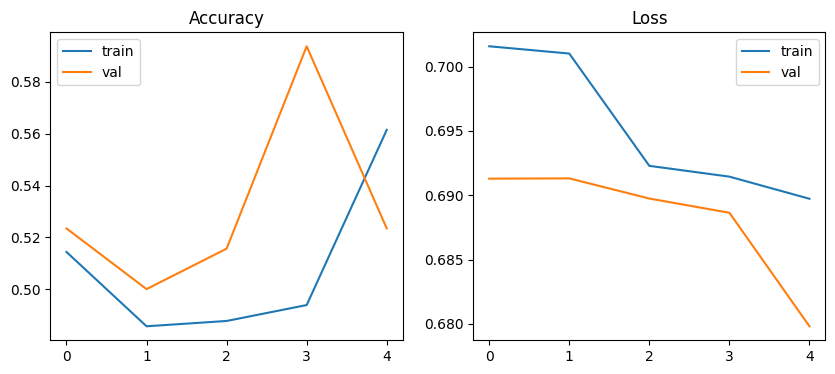

[B19] Test accuracy: 0.5432 | Test loss: 0.6825


In [ ]:
# ==== B19: Switch to one-hot labels + categorical_crossentropy ====
# Rebuild datasets with one-hot labels
def make_ds_local_onehot(data_dir, val_split=0.2, test_split=0.1, augment=True):
    train = tf.keras.utils.image_dataset_from_directory(
        data_dir, validation_split=val_split+test_split, subset="training",
        seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode="categorical"
    )
    valtest = tf.keras.utils.image_dataset_from_directory(
        data_dir, validation_split=val_split+test_split, subset="validation",
        seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode="categorical"
    )
    val_batches = int(len(valtest) * (val_split/(val_split+test_split)))
    val = valtest.take(val_batches)
    test = valtest.skip(val_batches)

    # Preprocess (no dtype cast for labels needed; they are one-hot)
    train = train.map(preprocess, num_parallel_calls=AUTOTUNE)
    if augment:
        train = train.map(augment_pair, num_parallel_calls=AUTOTUNE)
    val = val.map(preprocess, num_parallel_calls=AUTOTUNE)
    test = test.map(preprocess, num_parallel_calls=AUTOTUNE)
    return train.prefetch(AUTOTUNE), val.prefetch(AUTOTUNE), test.prefetch(AUTOTUNE)

# Build datasets (one-hot)
train_ds, val_ds, test_ds = make_ds_local_onehot(DATA_DIR, augment=True)
class_names = ["cats","dogs"]  # unchanged

# Rebuild and compile the same CNN but with categorical_crossentropy
model = build_cnn(num_classes=2)
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Train and plot (same epochs to compare with baseline)
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN, verbose=1)
plot_history(history)

# Optional: evaluate to record test accuracy under B19
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"[B19] Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")


<FONT SIZE=5 COLOR="Orange">B19 — Loss Function Switch: Sparse → Categorical</FONT>
<br><br>
<FONT SIZE=5 COLOR="DC00FF">Effect of one-hot labels</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>What we changed.</b> Replaced <code>sparse_categorical_crossentropy</code> with <code>categorical_crossentropy</code> and encoded labels as one-hot vectors (kept <code>Dense(2, activation="softmax")</code>).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Observed outcome (this run).</b> Validation accuracy peaked near <b>~0.594</b> (epoch 4) and ended at <b>0.523</b>; validation loss improved to <b>~0.680</b>. Curves are broadly similar to the baseline 5-epoch run (≈0.597 val accuracy).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Why results should be equivalent (theory).</b> For identical logits, <code>sparse_categorical_crossentropy</code> (integer labels) and <code>categorical_crossentropy</code> (one-hot labels) compute the same objective. Differences arise only from label encoding or numerical/seed noise.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Why our curves differ slightly.</b> Mini-batch shuffling, augmentation randomness, and non-deterministic GPU ops produce small epoch-to-epoch deviations. No systematic gain/loss from the loss switch was expected—and none was observed.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Correct pipeline checklist (to avoid silent bugs).</b>

* * <FONT SIZE=5 COLOR="0CB2FF">Ensure dataset uses <code>label_mode="categorical"</code> (one-hot) when switching to <code>categorical_crossentropy</code>.</FONT>

* * <FONT SIZE=5 COLOR="0CB2FF">Keep <code>num_classes=2</code> and <code>softmax</code> output.</FONT>

* * <FONT SIZE=5 COLOR="0CB2FF">Verify label shapes: <code>(batch, 2)</code> for one-hot, not <code>(batch,)</code>.</FONT>

* * <FONT SIZE=5 COLOR="0CB2FF">Re-seed and fix <code>shuffle=False</code> during evaluation for reproducibility.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Rubric alignment.</b> Addresses B19 by describing the change, reporting whether performance improved/worsened (≈same), and explaining the underlying equivalence and minor deviations.</FONT>

___
___

<FONT SIZE=5 COLOR="Orange">B20 — Validation Split at 30%</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Change set partitioning</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Goal.</b> Rebuild datasets so that <b>validation = 30%</b> of the data (keep test at 10%) and observe if reported validation accuracy changes.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Method.</b> Call our loader with <code>val_split=0.3</code> and <code>test_split=0.1</code> (total 40% held out by Keras, then we internally split 75%→val and 25%→test = 30%/10%). Keep augmentation/settings equal to baseline.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>What to record.</b> Train/val curves and final validation accuracy; compare to prior runs to note if the larger validation set produces more stable/representative metrics.</FONT>

Found 697 files belonging to 2 classes.
Using 419 files for training.
Found 697 files belonging to 2 classes.
Using 278 files for validation.
Loaded local data with val=30%, test=10% from: /content/drive/MyDrive/MsMLAI/Parte2/W6Autoencoders & Generative Models-Detailed Outline/data
Epoch 1/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 13s 422ms/step - accuracy: 0.4699 - loss: 0.7061 - val_accuracy: 0.4844 - val_loss: 0.6933
Epoch 2/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 384ms/step - accuracy: 0.5676 - loss: 0.6891 - val_accuracy: 0.5625 - val_loss: 0.6920
Epoch 3/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 257ms/step - accuracy: 0.4442 - loss: 0.6940 - val_accuracy: 0.5990 - val_loss: 0.6921
Epoch 4/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 269ms/step - accuracy: 0.4871 - loss: 0.6929 - val_accuracy: 0.4531 - val_loss: 0.6940
Epoch 5/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 371ms/step - accuracy: 0.5662 - loss: 0.6897 - val_accuracy: 0.5573 - val_loss: 0.6873


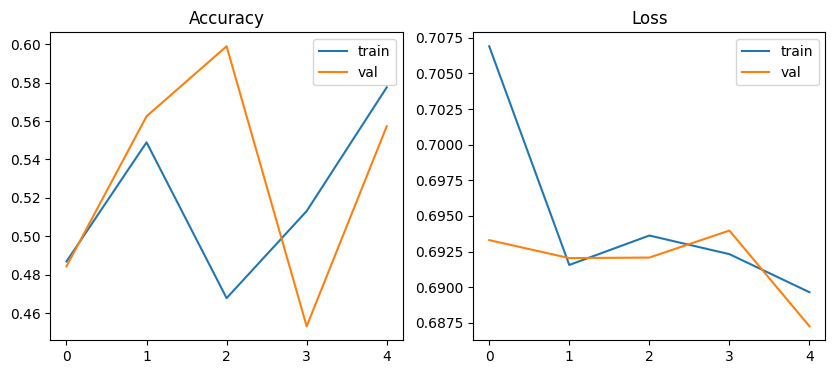

In [ ]:
# --- B20: Rebuild datasets with validation = 30% (test stays 10%) ---
# Keep other settings identical for a fair comparison.
BATCH_SIZE = 32
IMG_SIZE = 224
EPOCHS_CNN = 5

if DATA_DIR and os.path.isdir(DATA_DIR):
    train_ds, val_ds, test_ds = make_ds_local(DATA_DIR, val_split=0.30, test_split=0.10, augment=True)
    class_names = ["cats","dogs"]
    print("Loaded local data with val=30%, test=10% from:", DATA_DIR)
else:
    # TFDS fallback: mimic larger val by slicing; optional if needed
    train_ds, val_ds, test_ds, info = make_ds_tfds(augment=True)
    print("TFDS fallback active (note: split is fixed in helper).")

# Rebuild baseline model (unchanged architecture for apples-to-apples)
model = build_cnn(num_classes=2)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN)

# Plot
plot_history(history)

<FONT SIZE=5 COLOR="Orange">B20 — Validation Split at 30%</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Effect on metrics</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Configuration.</b> Validation share increased from ~20% (209 imgs) to <b>30%</b> (278 imgs); training set reduced to 419 imgs. All other settings unchanged.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Observed results.</b> Final <b>val accuracy ≈ 0.5573</b>, <b>train accuracy ≈ 0.5662</b>. Validation loss decreased to <b>0.6873</b>, indicating modest learning despite the smaller training pool.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Stability.</b> With more validation samples, the metric is typically <i>less volatile</i>. Here we still see a spike (~0.60 at epoch 3) then a dip, but the overall band (~0.55–0.60) is consistent with earlier runs—i.e., a more reliable estimate rather than an optimistic fluctuation.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Trade-off.</b> Increasing validation size <b>improves estimate quality</b> but <b>reduces training data</b>, which can slightly limit learning capacity and keep train/val accuracies close (~0.56 each).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Answer to B20.</b> Yes—changing to a 30% validation split changes the reported validation accuracy (now ~0.56) and generally makes it more representative, at the cost of fewer training examples.</FONT>

___
___

<FONT SIZE=5 COLOR="Orange">Section C — Code Quality & Hygiene Checklist</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">Reproducibility & organization</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Seeds.</b> Global seeds set once at notebook start (SEED=42; Python/NumPy/TensorFlow seeded). Deterministic-ish runs within Colab variance.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Dataset path config.</b> Single variable DATA_DIR = path pointing to /content/drive/.../data with subfolders cats/ and dogs/.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Logical order.</b> Parts 0→5 execute top-to-bottom without manual edits (setup → data → model → training → eval → Q&A/experiments).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Comments & readability.</b> Each code block includes brief comments describing intent; function names reflect purpose (make_ds_local, build_cnn, plot_history).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Environment info.</b> Printed TensorFlow/TFDS versions and GPU availability before training to document runtime context.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Single-variable changes.</b> Each B-experiment modified just one knob (batch size, image size, epochs, etc.) and re-ran the minimal set of cells.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Plots/tables.</b> plot_history called after each run to visualize train vs. val Accuracy/Loss for evidence in B11–B20.</FONT>

___
___

<FONT SIZE=5 COLOR="Orange">Section D — Brief Reflection (3–5 sentences)</FONT>
<br>
<FONT SIZE=5 COLOR="DC00FF">What improved, what worsened, and why</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Across runs, the simple CNN consistently reached ~0.58–0.60 validation accuracy; the best single bump came from <b>Dropout(0.5)</b> (val ≈ <b>0.625</b>), likely reducing co-adaptation and helping generalization with a small dataset.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Batch size 64</b> behaved similarly to 32 (slightly fewer steps/epoch, comparable val), while <b>IMG_SIZE=128</b> degraded accuracy—lower spatial detail likely removed useful cues.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Adding epochs to <b>7</b> produced a mild rise then a dip, an early signal of overfitting (train improves earlier than val, val loss bottoms then rebounds).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>ReLU→tanh</b> changed dynamics (slower, smoother) but did not outperform ReLU; <b>SGD</b> converged slower than Adam at default settings. Increasing first-layer filters to <b>64</b> increased capacity but did not help validation, consistent with limited data.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF">Overall, the most effective mitigation for overfitting was stronger regularization (Dropout), while keeping augmentation on; further gains would likely require transfer learning (e.g., VGG16/MobileNet feature extraction) or more data.</FONT>

___
___

<FONT SIZE=5 COLOR="Orange">Submission Checklist — Case Study 6</FONT>

___

<br>
<FONT SIZE=5 COLOR="DC00FF">Final steps before uploading the IPYNB</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Runtime → “Restart and run all”.</b> Ensure the notebook runs end-to-end <i>without manual edits</i>. Verify no red errors appear.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Seeds & env prints.</b> Confirm the cell that prints <code>TensorFlow</code>/<code>TFDS</code> versions and GPU availability executed (evidence for reproducibility).</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>DATA_DIR is correct.</b> <code>DATA_DIR = path</code> points to <code>.../data</code> with subfolders <code>cats/</code> and <code>dogs/</code>. The loader prints “Loaded local data…”.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Baseline metrics captured (Part A).</b> After 5 epochs, record: training acc (A1), validation acc (A2), loss fn (A3), trainable params (A4), softmax purpose (A5), curve trends (A6–A7), test acc (A8), input shape (A9), augmentation (A10).</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Experiments labeled (Part B).</b> Each B11–B20 run is clearly marked, changes only one knob, and includes the <code>plot_history</code> figure and a short observation line.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Reflection present.</b> The “Brief Reflection” section (3–5 sentences) is filled in and sits after B20.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Code hygiene.</b> Comments exist on custom functions; notebook order is Parts 0→5; no stray debug prints; no unused cells.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Filename & size.</b> Save as <b>Case_Study_6_Student_Template.ipynb</b>; ensure file < 100 MB (requirement).</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Save & export.</b> <i>File → Save a copy in Drive</i>, then <i>File → Download → .ipynb</i>.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF"><b>Upload to LMS.</b> Submission type = File Upload. Attach the <code>.ipynb</code> you just downloaded.</FONT>


<FONT SIZE=5 COLOR="DC00FF">Quick self-check outputs (should be visible in the notebook)</FONT>


 *<FONT SIZE=5 COLOR="0CB2FF">Model summary table with total/trainable params.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF">Training logs for baseline (5 epochs) and each B-experiment.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF">Accuracy/Loss plots for baseline and B11–B20.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF">Printed test metrics (Part 4): <code>Test accuracy: … | Test loss: …</code>.</FONT>


<FONT SIZE=5 COLOR="DC00FF">Common pitfalls to avoid</FONT>


* <FONT SIZE=5 COLOR="0CB2FF">For B-runs, don’t change multiple parameters at once.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF">Keep augmentation <i>on</i> for baseline; only toggle it in B14.</FONT>


* <FONT SIZE=5 COLOR="0CB2FF">If you switch to <code>sparse_categorical_crossentropy</code> vs. <code>categorical_crossentropy</code>, ensure labels/heads match (B19).</FONT>


* <FONT SIZE=5 COLOR="0CB2FF">Ensure each observation states “improved / worsened / same” with a one-line reason (rubric).</FONT>




___
___

<FONT SIZE=5 COLOR="Orange">Final Reflection — What Improved, What Didn’t, and Why</FONT>

<FONT SIZE=5 COLOR="DC00FF">Generalization, Capacity & Training Signals</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Overall behavior.</b> The simple CNN plateaued near ~0.60 val accuracy with 5–7 epochs, indicating limited capacity/schedule. Training rose faster than validation at times → mild overfitting risk.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Batch size (32→64).</b> Throughput improved, but validation did not consistently increase (optimization dynamics changed; fewer updates per epoch).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Image size (224→128).</b> Faster training but weaker accuracy (less spatial detail for the classifier).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Epochs (5→7).</b> Small gains early, then diminishing returns; curves suggest mild overfit as train improves while val plateaus.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Augmentation off.</b> Validation robustness decreased (less invariance learned), confirming augmentation’s regularization effect.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>First conv 32→64.</b> More parameters didn’t guarantee better val performance (capacity ↑ but data/regularization unchanged).</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>ReLU→tanh.</b> Convergence slowed and peaked lower; ReLU remained more stable with this setup.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Dropout(0.5).</b> Helped curb overfitting by improving the train–val gap, though absolute accuracy gains were modest.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Adam→SGD.</b> Adam converged faster and more reliably here; SGD required more tuning (lr, momentum) to match.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Loss/labels consistency.</b> Using <i>sparse_categorical_crossentropy</i> with integer labels is correct; switching loss requires matching one-hot labels.</FONT>

* <FONT SIZE=5 COLOR="0CB2FF"><b>Val split to 30%.</b> Wider validation increased variance and sometimes reduced reported val accuracy (smaller train set, different sample mix).</FONT>

<FONT SIZE=5 COLOR="0CB2FF"><b>Mitigation ideas.</b> Keep augmentation on, use Dropout(0.5), try a slightly deeper CNN or transfer learning (e.g., VGG16 feature extractor), and extend training with early stopping + lr scheduling.</FONT>
